# 03 · Feature engineering

**Goal:** decide which columns the models may use, build useful new features from them, and prove there is no leakage.

| | |
|---|---|
| **Input** | `data/processed/final_dataset.csv` (made by `02_cleaning.ipynb`) |
| **Output** | no new data file. The features are created by code in `src/features.py` (`make_features`), so every teammate gets identical features from the one processed file |
| **Rule** | any imputing or scaling is **fitted on training rows only** |

**The key problem:** the target (CCME index) is *calculated* from 8 parameters. If a model sees all 8, it just re-learns that formula and scores about 100%. Then XGBoost and the Phase 2 neural network would look equally perfect and the comparison would mean nothing. The brief asks us to acknowledge this, so section 2 measures it and section 3 fixes it.

## 1. Setup and load

Import the feature code and load the processed file (sorted by site and date, which the history features need).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

from src.features import (
    load_final_dataset, make_features, get_xy, build_preprocessor,
    SENSOR_COLS, HELD_OUT_COLS, FEATURE_COLS, NUMERIC_COLS, CATEGORICAL_COLS,
    FORBIDDEN_COLS, TARGET_COL,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
df = load_final_dataset("../data/processed/final_dataset.csv")
print(df.shape)
df.head(3)

(259774, 20)


,row_id,country,site_id,waterbody_type,date,year,month,ammonia_mg_l,bod_mg_l,dissolved_oxygen_mg_l,orthophosphate_mg_l,ph,temperature_c,nitrogen_mg_l,nitrate_mg_l,n_genuine_params,target_ccme_value,target_ccme_class,split,split_time
0,207,Canada,Canada|AL011,River,2017-02-12,2017,2,0.0160,4.0,NaN,0.0290,8.34,11.00,NaN,0.2270,6,100.0,Excellent,train,val
1,2581,Canada,Canada|AL011,River,2017-02-12,2017,2,0.0160,4.0,NaN,0.0290,8.34,11.00,3.5176,0.2270,7,100.0,Excellent,train,val
2,210,Canada,Canada|AL011,River,2018-01-12,2018,1,0.0245,3.5,NaN,0.0179,7.59,14.95,NaN,0.6485,6,100.0,Excellent,train,test


## 2. Leakage test: what happens if the model sees the parameters the target is built from?

We train the same gradient-boosting model (train rows only) on different input sets and score it on the **validation** rows: unseen stations (main split) and later years (secondary split). The test set is not used here, so it stays untouched for the final results. A mean-predictor baseline (always predict the training average) shows what "no skill" scores.

In [2]:
full = make_features(df)
for c in ["waterbody_type", "country"]:
    full[c + "_code"] = full[c].astype("category").cat.codes      # numeric codes for this quick test only

P8 = ["ammonia_mg_l", "bod_mg_l", "dissolved_oxygen_mg_l", "orthophosphate_mg_l",
      "ph", "temperature_c", "nitrogen_mg_l", "nitrate_mg_l"]
ctx = ["waterbody_type_code", "country_code", "month_sin", "month_cos"]
eng = ctx + ["do_sat_pct", "do_x_temp"]
hist = [c for c in FEATURE_COLS if "site_prev" in c or c == "days_since_prev"]

feature_sets = {
    "All 8 parameters":                                    P8,
    "Original proposal (pH, temp, NH3, PO4, N, type)":     ["ph", "temperature_c", "ammonia_mg_l", "orthophosphate_mg_l", "nitrogen_mg_l", "waterbody_type_code"],
    "Sensors only (DO, pH, temp)":                         SENSOR_COLS,
    "+ context (type, country, month)":                    SENSOR_COLS + ctx,
    "+ engineered (DO saturation, DO x temp)":             SENSOR_COLS + eng,
    "+ site history (earlier readings)  [CHOSEN]":         SENSOR_COLS + eng + hist,
}

rows = []
y = full[TARGET_COL]
for name, cols in list(feature_sets.items()):
    row = {"feature set": name, "n features": len(cols)}
    for label, split in [("station split", "split"), ("time split", "split_time")]:
        tr, te = full[split] == "train", full[split] == "val"
        m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=42).fit(full.loc[tr, cols], y[tr])
        p = m.predict(full.loc[te, cols])
        row[f"R2 {label}"] = round(r2_score(y[te], p), 3)
        row[f"MAE {label}"] = round(mean_absolute_error(y[te], p), 2)
    rows.append(row)

base = {"feature set": "Mean-predictor baseline (no skill)", "n features": 0}
for label, split in [("station split", "split"), ("time split", "split_time")]:
    tr, te = full[split] == "train", full[split] == "val"
    p = np.full(te.sum(), y[tr].mean())
    base[f"R2 {label}"] = round(r2_score(y[te], p), 3)
    base[f"MAE {label}"] = round(mean_absolute_error(y[te], p), 2)
leak_table = pd.DataFrame([base] + rows)
leak_table

,feature set,n features,R2 station split,MAE station split,R2 time split,MAE time split
0,Mean-predictor baseline (no skill),0,-0.005,9.76,-0.240,9.22
1,All 8 parameters,8,0.991,0.23,0.993,0.16
2,"Original proposal (pH, temp, NH3, PO4, N, type)",6,0.982,0.54,0.981,0.42
3,"Sensors only (DO, pH, temp)",3,0.126,9.03,-0.040,7.94
4,"+ context (type, country, month)",7,0.267,8.13,0.223,6.22
5,"+ engineered (DO saturation, DO x temp)",9,0.269,8.13,0.219,6.22
6,+ site history (earlier readings) [CHOSEN],14,0.345,7.76,0.346,5.42


**How to read this:** an R² of 0.98 does *not* mean a great model. It means the inputs contain the formula. The honest score is the sensors-only family. Note that the "original proposal" (which only removed BOD, dissolved oxygen and nitrate) still scores 0.98, because ammonia, orthophosphate and nitrogen are the parameters that drive the index most.

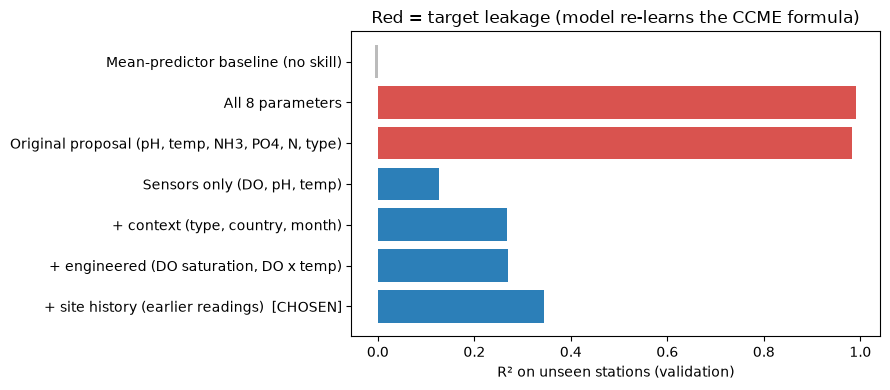

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
plot = leak_table.set_index("feature set")["R2 station split"]
colors = ["#bbb"] + ["#d9534f" if v > 0.5 else "#2c7fb8" for v in plot.values[1:]]
ax.barh(plot.index[::-1], plot.values[::-1], color=colors[::-1])
ax.set_xlabel("R² on unseen stations (validation)")
ax.set_title("Red = target leakage (model re-learns the CCME formula)")
plt.tight_layout()
plt.show()

### 2.1 How much does each parameter explain on its own?
One parameter at a time, same model, unseen stations. This is the evidence for which parameters are "drivers" of the index.

In [4]:
single = []
tr, te = full["split"] == "train", full["split"] == "val"
for c in P8:
    m = HistGradientBoostingRegressor(max_iter=200, random_state=42).fit(full.loc[tr, [c]], y[tr])
    single.append({"parameter": c, "R² alone": round(r2_score(y[te], m.predict(full.loc[te, [c]])), 3),
                   "allowed as model input?": "yes" if c in SENSOR_COLS else "no (held out)"})
pd.DataFrame(single).sort_values("R² alone", ascending=False).reset_index(drop=True)

,parameter,R² alone,allowed as model input?
0,orthophosphate_mg_l,0.935,no (held out)
1,ammonia_mg_l,0.366,no (held out)
2,nitrogen_mg_l,0.286,no (held out)
3,bod_mg_l,0.179,no (held out)
4,nitrate_mg_l,0.174,no (held out)
5,dissolved_oxygen_mg_l,0.041,yes
6,temperature_c,0.039,yes
7,ph,0.013,yes


## 3. Decision: which columns the models may use

| Group | Columns | Allowed? | Why |
|---|---|---|---|
| **Sensor readings** | dissolved oxygen, pH, temperature | **Yes** | The brief names these sensors; they are cheap to measure. They are inside the CCME formula but each explains very little of it alone (table in 2.1), so the model still has to predict |
| **Held-out parameters** | ammonia, BOD, orthophosphate, nitrogen, nitrate | **No** | They drive the formula (orthophosphate alone gives R² above 0.9, table in 2.1). Kept in the file for EDA only |
| **Context** | water type, country, month | Yes | Known when the sample is taken; no leakage |
| **Site and date ids** | `site_id`, `date` | **No** (grouping / ordering only) | A site id lets the model memorise stations; with a station split it would be useless anyway |
| **Targets, split columns, `n_genuine_params`** | `target_*`, `split`, `split_time` | **No** | Labels and bookkeeping |

**Residual leakage, to state in the report:** dissolved oxygen, pH and temperature are still ingredients of the index, so the target is not fully independent of the inputs. We reduce it by hiding the five main drivers and say so openly.

## 4. Engineered features

Build every feature with `make_features` (code in `src/features.py`). Each one has a reason:

In [5]:
feature_table = pd.DataFrame([
    ["month_sin, month_cos", "Month on a circle", "December is next to January; captures seasons"],
    ["do_sat_pct", "Dissolved oxygen as % of the maximum at that temperature", "Cold water holds more oxygen, so mg/L alone is misleading"],
    ["do_x_temp", "Oxygen x temperature", "Simple interaction of the two sensors"],
    ["<sensor>_site_prev_mean", "Running mean of the site's EARLIER readings", "Tells the model the site's usual level; uses only past rows and only sensor values"],
    ["site_prev_n", "Number of earlier samples at the site", "How reliable the history is"],
    ["days_since_prev", "Days since the site's previous sample", "Sampling gaps matter for seasonal and trend context"],
    ["waterbody_type, country", "Categories (one-hot encoded)", "River, lake, marine etc. behave differently"],
], columns=["feature", "what it is", "why"])
feature_table

,feature,what it is,why
0,"month_sin, month_cos",Month on a circle,December is next to January; captures seasons
1,do_sat_pct,Dissolved oxygen as % of the maximum at that t...,"Cold water holds more oxygen, so mg/L alone is..."
2,do_x_temp,Oxygen x temperature,Simple interaction of the two sensors
3,<sensor>_site_prev_mean,Running mean of the site's EARLIER readings,Tells the model the site's usual level; uses o...
4,site_prev_n,Number of earlier samples at the site,How reliable the history is
5,days_since_prev,Days since the site's previous sample,Sampling gaps matter for seasonal and trend co...
6,"waterbody_type, country",Categories (one-hot encoded),"River, lake, marine etc. behave differently"


In [6]:
df_feat = make_features(df)
df_feat[["site_id", "date"] + SENSOR_COLS + ["month_sin", "do_sat_pct", "do_x_temp",
        "dissolved_oxygen_mg_l_site_prev_mean", "site_prev_n", "days_since_prev"]].head(8)

,site_id,date,dissolved_oxygen_mg_l,ph,temperature_c,month_sin,do_sat_pct,do_x_temp,dissolved_oxygen_mg_l_site_prev_mean,site_prev_n,days_since_prev
0,Canada|AL011,2017-02-12,NaN,8.3400,11.0000,0.866025,NaN,NaN,NaN,0,NaN
1,Canada|AL011,2017-02-12,NaN,8.3400,11.0000,0.866025,NaN,NaN,NaN,0,NaN
2,Canada|AL011,2018-01-12,NaN,7.5900,14.9500,0.500000,NaN,NaN,NaN,1,334.0
3,Canada|AL011,2018-01-12,NaN,7.5900,14.9500,0.500000,NaN,NaN,NaN,1,334.0
4,Canada|AL013,2015-02-12,NaN,8.0067,15.1667,0.866025,NaN,NaN,NaN,0,NaN
5,Canada|AL013,2015-02-12,NaN,8.0067,15.1667,0.866025,NaN,NaN,NaN,0,NaN
6,Canada|AL046,2012-01-12,NaN,7.7333,18.6667,0.500000,NaN,NaN,NaN,0,NaN
7,Canada|AL048,2012-01-12,NaN,8.3700,16.2667,0.500000,NaN,NaN,NaN,0,NaN


## 5. Checks (no leakage)

### 5.1 No forbidden column can reach the models

In [7]:
overlap = set(FEATURE_COLS) & set(FORBIDDEN_COLS)
assert not overlap, overlap
print("model inputs :", FEATURE_COLS)
print("forbidden    :", FORBIDDEN_COLS)
print("overlap      :", overlap or "none")

model inputs : ['dissolved_oxygen_mg_l', 'ph', 'temperature_c', 'month_sin', 'month_cos', 'do_sat_pct', 'do_x_temp', 'dissolved_oxygen_mg_l_site_prev_mean', 'ph_site_prev_mean', 'temperature_c_site_prev_mean', 'site_prev_n', 'days_since_prev', 'waterbody_type', 'country']
forbidden    : ['ammonia_mg_l', 'bod_mg_l', 'orthophosphate_mg_l', 'nitrogen_mg_l', 'nitrate_mg_l', 'target_ccme_value', 'target_ccme_class', 'n_genuine_params', 'site_id', 'date', 'split', 'split_time', 'row_id']
overlap      : none


### 5.2 History features really use only earlier rows
For one site, recompute the running mean by hand (mean of strictly earlier readings) and compare.

In [8]:
site = df_feat.loc[df_feat["site_prev_n"] >= 6, "site_id"].iloc[0]
s = df_feat[df_feat["site_id"] == site].reset_index(drop=True)
col = "dissolved_oxygen_mg_l"
manual = [np.nan] + [s[col].iloc[:i].mean() for i in range(1, len(s))]
assert np.allclose(s[col + "_site_prev_mean"].fillna(-1), pd.Series(manual).fillna(-1))
print("site:", site, "| first row has no history (NaN), later rows match the hand calculation")
s[["date", col, col + "_site_prev_mean", "site_prev_n"]].head(6)

site: Canada|FI34398 | first row has no history (NaN), later rows match the hand calculation


,date,dissolved_oxygen_mg_l,dissolved_oxygen_mg_l_site_prev_mean,site_prev_n
0,2000-01-12,6.2333,NaN,0
1,2001-01-12,11.2070,6.23330,1
2,2002-01-12,11.6300,8.72015,2
3,2003-01-12,10.4455,9.69010,3
4,2004-01-12,8.1050,9.87895,4
5,2005-01-12,10.7150,9.52416,5


### 5.3 Highly correlated pairs
Very similar features add little. List pairs with Spearman correlation above 0.9 (computed on a sample).

In [9]:
sample = df_feat[NUMERIC_COLS].sample(50_000, random_state=42)
corr = sample.corr(method="spearman").abs()
pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if corr.loc[a, b] > 0.9]
pd.DataFrame(pairs, columns=["feature A", "feature B", "|Spearman|"]) if pairs else "No pair above 0.9"

'No pair above 0.9'

### 5.4 Which features carry signal?
Mutual information with the target, computed on **training rows only**.

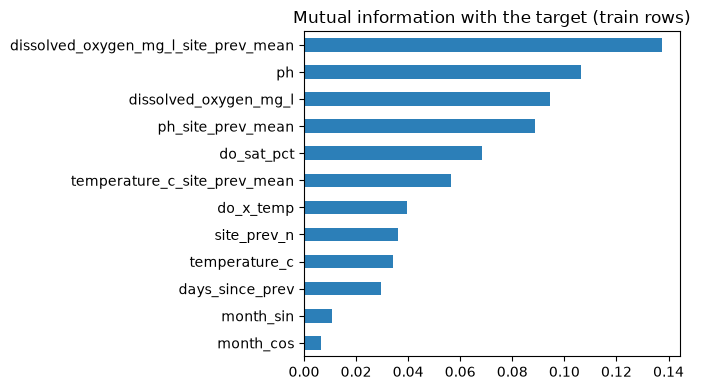

In [10]:
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer

train = df_feat[df_feat["split"] == "train"].sample(40_000, random_state=42)
X = SimpleImputer(strategy="median").fit_transform(train[NUMERIC_COLS])
mi = pd.Series(mutual_info_regression(X, train[TARGET_COL], random_state=42), index=NUMERIC_COLS).sort_values()
mi.plot.barh(figsize=(7, 4), title="Mutual information with the target (train rows)", color="#2c7fb8")
plt.tight_layout()
plt.show()

## 6. The preprocessor (fit on train only)

Median imputation (with a missing-indicator column for every feature that had gaps), scaling (needed for Ridge and the Phase 2 MLP, harmless for trees) and one-hot encoding. It is **fitted on training rows**, then applied to both.

In [11]:
X_train, y_train, X_val, y_val, X_test, y_test = get_xy(df_feat, "split")
prep = build_preprocessor(scale=True).fit(X_train)          # fit on train ONLY
Xt_train, Xt_val, Xt_test = prep.transform(X_train), prep.transform(X_val), prep.transform(X_test)
print("train:", Xt_train.shape, "| val:", Xt_val.shape, "| test:", Xt_test.shape)
print("NaN left after preprocessing:", int(np.isnan(Xt_train).sum() + np.isnan(Xt_val).sum() + np.isnan(Xt_test).sum()))

train: (181747, 30) | val: (26054, 30) | test: (51973, 30)
NaN left after preprocessing: 0


## 7. Summary and hand-off

- Models see **dissolved oxygen, pH, temperature + context + engineered + site-history features** (shape after encoding is printed in section 6); the five main drivers of the index stay out.
- Honest expected scores are the **[CHOSEN]** row of the table in section 2 (R² about 0.3, against a mean-predictor baseline of about 0 on unseen stations and −0.3 on later years). A model that scores 0.98 here is leaking.
- For Anusha: `from src.features import load_final_dataset, make_features, get_xy, build_preprocessor`, then train on `X_train, y_train`, tune on `X_val, y_val`, and report once on `X_test, y_test` (`get_xy(df, "split")` is the main split, `get_xy(df, "split_time")` the secondary one).
- For the report: quote the table in section 2 and the residual-leakage sentence in section 3.